# 1. Import Library

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

# 2. Load Dataset

In [2]:
import pandas as pd

data = pd.read_csv("D:/NLP/Modul-2/dataset_preprocessed.csv")
text_column = "processed_text"

data = data.dropna(subset=[text_column])

# Gunakan sample untuk eksperimen awal
sample = data[text_column].head(1000).astype(str).tolist()
print(f"Jumlah dokumen sample: {len(sample)}")

print("Ukuran dataset:", data.shape)
print("Kolom:", data.columns.tolist())

Jumlah dokumen sample: 1000
Ukuran dataset: (119676, 2)
Kolom: ['content', 'processed_text']


In [18]:
# Pilih kolom teks hasil preprocessing
data = data.copy()

preferred_text_columns = [
    "processed_text", "stemming", "cleaning", "content", "text"
]
text_column = next(
    (column for column in preferred_text_columns if column in data.columns),
    None
)

if text_column is None:
    object_columns = data.select_dtypes(
        include=["object", "string"]
    ).columns.tolist()
print("Kolom teks terpilih:", text_column)

data[text_column] = data[text_column].fillna("").astype(str).str.strip()
data_text = data[data[text_column].ne("")].copy()

# Hapus duplikat teks untuk mengurangi dokumen yang sama persis berulang.
# Jika ingin mempertahankan semua ulasan, hapus baris drop_duplicates ini.
data_text = data_text.drop_duplicates(subset=[text_column]).reset_index(drop=True)

print("Jumlah dokumen teks yang valid dan unik:", len(data_text))
sample_size = min(1000, len(data_text))
sample = data_text[text_column].head(sample_size).tolist()
print(f"Jumlah dokumen sample untuk eksperimen: {len(sample)}")

Kolom teks terpilih: processed_text
Jumlah dokumen teks yang valid dan unik: 65556
Jumlah dokumen sample untuk eksperimen: 1000


# 3. Bag of Words dengan CountVectorizer

In [19]:
vectorizer_bow = CountVectorizer(max_features=5000)
bow_matrix = vectorizer_bow.fit_transform(sample)

vocab_bow = vectorizer_bow.get_feature_names_out()
print("Shape matriks BoW:", bow_matrix.shape)
print("Jumlah vocabulary:", len(vocab_bow))
print("Contoh vocabulary:", vocab_bow[:20])

Shape matriks BoW: (1000, 1681)
Jumlah vocabulary: 1681
Contoh vocabulary: ['aamiin' 'aaplikasi' 'abis' 'acc' 'account' 'acount' 'ad' 'ada'
 'adapusing' 'admin' 'administrasi' 'adminya' 'adu' 'ae' 'affiliate' 'afk'
 'aflikasi' 'aga' 'agk' 'ah']


In [5]:
# Melihat representasi satu dokumen:
doc_vector = bow_matrix[0].toarray()[0]
nonzero_indices = np.where(doc_vector > 0)[0]

print("Dokumen pertama:")
print(sample[0])
print("\nRepresentasi BoW (kata dengan frekuensi > 0):")
for idx in nonzero_indices:
    print(f"{vocab_bow[idx]:<20} : {int(doc_vector[idx])}")

Dokumen pertama:
mantap

Representasi BoW (kata dengan frekuensi > 0):
mantap               : 1


# Statistik Matriks BoW

In [6]:
# Sparsity
total_elements = bow_matrix.shape[0] * bow_matrix.shape[1]
nonzero_elements = bow_matrix.nnz
sparsity = 1 - (nonzero_elements / total_elements) if total_elements else 0

print(f"Total elemen matriks : {total_elements:,}")
print(f"Elemen non-zero      : {nonzero_elements:,}")
print(f"Sparsity             : {sparsity:.4%}")

Total elemen matriks : 1,681,000
Elemen non-zero      : 5,353
Sparsity             : 99.6816%


# TF-IDF dengan TfidfVectorizer

In [7]:
vectorizer_tfidf = TfidfVectorizer(max_features=5000)
tfidf_matrix = vectorizer_tfidf.fit_transform(sample)
feature_names = vectorizer_tfidf.get_feature_names_out()

print("Shape matriks TF-IDF:", tfidf_matrix.shape)
print("Jumlah fitur TF-IDF:", len(feature_names))

Shape matriks TF-IDF: (1000, 1681)
Jumlah fitur TF-IDF: 1681


In [8]:
# Melihat kata dengan skor TF-IDF tertinggi pada dokumen tertentu:

def top_tfidf_words(doc_index, tfidf_mat, feature_names, top_n=10):
    row = tfidf_mat[doc_index].toarray().ravel()
    indices = row.argsort()[::-1]
    return [(feature_names[i], float(row[i])) for i in indices if row[i] > 0][:top_n]

print("Dokumen pertama:")
print(sample[0][:300])
print("\nTop kata TF-IDF pada dokumen pertama:")
for word, score in top_tfidf_words(0, tfidf_matrix, feature_names, top_n=10):
    print(f"{word:<20} : {score:.4f}")

Dokumen pertama:
mantap

Top kata TF-IDF pada dokumen pertama:
mantap               : 1.0000


# Cosine Similarity

In [9]:
# Hitung similarity antar dokumen:

n_docs_similarity = min(5, tfidf_matrix.shape[0])
subset = tfidf_matrix[:n_docs_similarity]
sim_matrix = cosine_similarity(subset)

print(f"Cosine Similarity Matrix ({n_docs_similarity} dokumen):")
display(pd.DataFrame(
    np.round(sim_matrix, 3),
    index=[f"D{i+1}" for i in range(n_docs_similarity)],
    columns=[f"D{i+1}" for i in range(n_docs_similarity)]
))

Cosine Similarity Matrix (5 dokumen):


,D1,D2,D3,D4,D5
D1,1.000,0.0,0.0,0.289,0.0
D2,0.000,1.0,0.0,0.000,0.0
D3,0.000,0.0,1.0,0.000,0.0
D4,0.289,0.0,0.0,1.000,0.0
D5,0.000,0.0,0.0,0.000,1.0


# Visualisasi Similarity Matrix

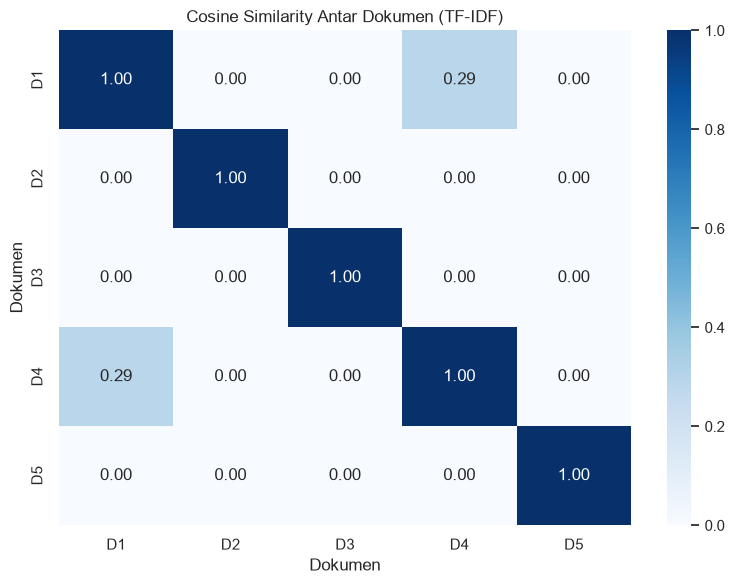

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    sim_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=[f"D{i+1}" for i in range(n_docs_similarity)],
    yticklabels=[f"D{i+1}" for i in range(n_docs_similarity)],
    vmin=0,
    vmax=1
)
plt.title("Cosine Similarity Antar Dokumen (TF-IDF)")
plt.xlabel("Dokumen")
plt.ylabel("Dokumen")
plt.tight_layout()
plt.show()

# Document Retrieval Sederhana

In [11]:
# Diberikan query, cari dokumen paling mirip:

def search_documents(query, vectorizer, tfidf_mat, docs, top_n=5):
    query_vec = vectorizer.transform([query])
    similarities = cosine_similarity(query_vec, tfidf_mat).ravel()
    top_indices = similarities.argsort()[::-1][:top_n]
    return [
        {
            "index": int(idx),
            "similarity": float(similarities[idx]),
            "text": docs[idx]
        }
        for idx in top_indices
    ]

query = "aplikasi gopay transaksi saldo"
results = search_documents(query, vectorizer_tfidf, tfidf_matrix, sample, top_n=5)

print("Query:", query)
for rank, result in enumerate(results, start=1):
    print(f"\n{rank}. Indeks dokumen: {result['index']} | Similarity: {result['similarity']:.4f}")
    print(result["text"][:300])


Query: aplikasi gopay transaksi saldo

1. Indeks dokumen: 497 | Similarity: 0.6588
suka aplikasi gopay saldo

2. Indeks dokumen: 40 | Similarity: 0.5340
gopay mudah transaksi

3. Indeks dokumen: 797 | Similarity: 0.4360
gopay aplikasi bantu

4. Indeks dokumen: 451 | Similarity: 0.4198
butuh gopay transaksi

5. Indeks dokumen: 254 | Similarity: 0.4166
pakai gopay mudah transaksi


# Perbandingan BoW vs TF-IDF

In [12]:
print("=" * 50)
print("PERBANDINGAN BOW vs TF-IDF")
print("=" * 50)

# Ambil 1 dokumen
doc_idx = 0
bow_vec = vectorizer_bow.transform([sample[doc_idx]]).toarray()[0]
tfidf_vec = vectorizer_tfidf.transform([sample[doc_idx]]).toarray()[0]

bow_vocab = vectorizer_bow.get_feature_names_out()
tfidf_vocab = vectorizer_tfidf.get_feature_names_out()

print(f"\nDokumen: {sample[doc_idx][:100]}...")
print("\nTop 10 Kata — BoW (frekuensi):")
top_bow = sorted(
    [(bow_vocab[i], bow_vec[i]) for i in range(len(bow_vec)) if bow_vec[i] > 0],
    key=lambda x: x[1], reverse=True
)[:10]
for word, val in top_bow:
    print(f"  {word:<20} : {int(val)}")

print("\nTop 10 Kata — TF-IDF (bobot):")
for word, score in top_tfidf_words(doc_idx, tfidf_matrix, tfidf_vocab):
    print(f"  {word:<20} : {score:.4f}")

PERBANDINGAN BOW vs TF-IDF

Dokumen: mantap...

Top 10 Kata — BoW (frekuensi):
  mantap               : 1

Top 10 Kata — TF-IDF (bobot):
  mantap               : 1.0000


## Tugas Analisis

In [13]:
# Persiapan — muat data dan buat representasi
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from IPython.display import display

data = pd.read_csv("D:/NLP/Modul-2/dataset_preprocessed.csv")
data = data.dropna(subset=["processed_text"]).copy()
data["processed_text"] = data["processed_text"].astype(str).str.strip()
data = data[data["processed_text"] != ""].reset_index(drop=True)

count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(data["processed_text"])

tfidf_transformer = TfidfTransformer()
tfidf_matrix = tfidf_transformer.fit_transform(bow_matrix)

print("Jumlah dokumen:", len(data))
print("Ukuran kosakata:", len(count_vectorizer.get_feature_names_out()))

Jumlah dokumen: 119613
Ukuran kosakata: 32654


In [14]:
# Nomor 1: Pilih 3 dokumen dari dataset. Hitung cosine similarity di antara keduanya menggunakan TF-IDF. Mana yang paling mirip?
from itertools import combinations

doc_indices = [0, 1, 2]  # Ganti indeks jika ingin memilih dokumen lain

selected_tfidf = tfidf_matrix[doc_indices]
similarity_matrix = cosine_similarity(selected_tfidf)

display(pd.DataFrame(
    similarity_matrix,
    index=[f"Dokumen {i}" for i in doc_indices],
    columns=[f"Dokumen {i}" for i in doc_indices],
))

pairs = [
    (similarity_matrix[i, j], doc_indices[i], doc_indices[j])
    for i, j in combinations(range(len(doc_indices)), 2)
]
score, doc_a, doc_b = max(pairs)

print(f"Pasangan paling mirip: dokumen {doc_a} dan {doc_b}")
print(f"Cosine similarity: {score:.4f}")
print("\nTeks dokumen:")
print(f"{doc_a}: {data.loc[doc_a, 'content']}")
print(f"{doc_b}: {data.loc[doc_b, 'content']}")
for nomor, idx in enumerate(doc_indices, start=1):
    print(f"Dokumen {nomor} (indeks {idx}):")
    print(data.loc[idx, "content"])
    print()

,Dokumen 0,Dokumen 1,Dokumen 2
Dokumen 0,1.0,0.0,0.0
Dokumen 1,0.0,1.0,0.0
Dokumen 2,0.0,0.0,1.0


Pasangan paling mirip: dokumen 1 dan 2
Cosine similarity: 0.0000

Teks dokumen:
1: Bagus dan mudah digunakan
2: Good
Dokumen 1 (indeks 0):
Mantap

Dokumen 2 (indeks 1):
Bagus dan mudah digunakan

Dokumen 3 (indeks 2):
Good



Dari hasil, “Bagus dan mudah digunakan” dan “Good” memiliki skor 0,0000. Artinya, TF-IDF tidak menemukan kata yang sama di antara keduanya. Pada matriks sebelumnya semua skor di luar diagonal juga 0.0, jadi ketiga pasangan sama rendah kemiripannya—belum ada satu pasangan yang paling mirip secara unik.

In [15]:
# nomor 2: Buat query baru dan jalankan document retrieval. Apakah hasilnya relevan?
query = "aplikasi gopay transaksi mudah"

query_bow = count_vectorizer.transform([query])
query_tfidf = tfidf_transformer.transform(query_bow)

if query_tfidf.nnz == 0:
    print("Tidak ada kata query yang cocok dengan kosakata dataset. Coba query lain.")
else:
    scores = cosine_similarity(query_tfidf, tfidf_matrix).ravel()
    top_indices = np.argsort(scores)[::-1][:5]

    print("Query:", query)
    for rank, idx in enumerate(top_indices, start=1):
        print(f"{rank}. Skor {scores[idx]:.4f} — {data.loc[idx, 'content']}")

Query: aplikasi gopay transaksi mudah
1. Skor 1.0000 — Dengan aplikasi gopay ini memudahkan kita untuk transaksi 🙂
2. Skor 1.0000 — Aplikasi gopay sangat mudah untuk transaksi apa saja
3. Skor 0.8938 — aplikasinya mempermudah untuk transaksi
4. Skor 0.8938 — Aplikasi yang memudahkan kita buat transaksi
5. Skor 0.8938 — Aplikasi yang bisa memudahkan segala transaksi.


Hasil document retrieval relevan dengan query “aplikasi gopay transaksi mudah”. Lima hasil teratas membahas kemudahan menggunakan GoPay untuk bertransaksi. Dua hasil pertama memperoleh skor 1,0000, sedangkan tiga hasil berikutnya mendapat 0,8938. Ini menunjukkan kecocokan kata yang tinggi dengan query, meskipun skor tersebut mengukur kemiripan teks, bukan memastikan makna secara sempurna.

In [16]:
# Nomor 3: bandingkan BoW dan TF-IDF pada dokumen yang memiliki beberapa kata
from sklearn.preprocessing import normalize
import pandas as pd
from IPython.display import display

# Cari dokumen pertama dengan minimal 3 kata berbeda
doc_idx = next(
    (
        i for i, text in enumerate(data["processed_text"].fillna("").astype(str))
        if len(set(text.split())) >= 3
    ),
    None,
)

if doc_idx is None:
    print("Tidak ditemukan dokumen dengan minimal 3 kata berbeda.")
else:
    bow_normalized = normalize(bow_matrix[doc_idx], norm="l2").toarray().ravel()
    tfidf_scores = tfidf_matrix[doc_idx].toarray().ravel()
    terms = count_vectorizer.get_feature_names_out()

    comparison = pd.DataFrame({
        "Kata": terms,
        "BoW ternormalisasi": bow_normalized,
        "TF-IDF": tfidf_scores,
    })

    comparison = comparison[comparison["BoW ternormalisasi"] > 0].copy()
    comparison["Perubahan absolut"] = (
        comparison["TF-IDF"] - comparison["BoW ternormalisasi"]
    ).abs()

    print("Dokumen:", data.loc[doc_idx, "content"])
    print("Kata dengan perubahan skor terbesar:")
    display(comparison.sort_values(
        "Perubahan absolut",
        ascending=False,
    ).head(10))

Dokumen: Sangat membantu orang menengah mantap semoga sukses terus gopay
Kata dengan perubahan skor terbesar:


,Kata,BoW ternormalisasi,TF-IDF,Perubahan absolut
29121,tengah,0.377964,0.674584,0.296620
10256,gopay,0.377964,0.195812,0.182152
17321,mantap,0.377964,0.209476,0.168488
2975,bantu,0.377964,0.224087,0.153877
19408,moga,0.377964,0.316416,0.061548
21873,orang,0.377964,0.414516,0.036551
28225,sukses,0.377964,0.374908,0.003056


Pada dokumen “Sangat membantu orang menengah mantap semoga sukses terus gopay”, kata yang skornya berubah paling signifikan adalah “tengah”. Skor BoW ternormalisasinya 0,377964, sedangkan skor TF-IDF-nya 0,674584, sehingga perubahan absolutnya 0,296620—terbesar di antara kata-kata pada dokumen tersebut.

Ini menunjukkan bahwa TF-IDF memberi bobot lebih besar pada kata “tengah” karena kata itu lebih khas atau lebih jarang muncul di dokumen lain dibanding kata-kata yang lebih umum.

Nomor 4: Apa dampak sparsity pada performa komputasi?


Sparsity berarti sebagian besar elemen pada matriks teks bernilai nol karena setiap dokumen hanya memakai sebagian kecil dari seluruh kosakata. Dengan format sparse, komputer menyimpan nilai yang tidak nol saja, sehingga penggunaan memori dan perhitungan biasanya lebih hemat daripada menyimpan seluruh matriks padat.

Namun, jika jumlah kosakata sangat besar, matriks tetap memiliki banyak kemungkinan fitur. Ini dapat menambah biaya saat membangun representasi dan menjalankan operasi, seperti menghitung kemiripan antar banyak dokumen. Jadi, sparsity membantu efisiensi penyimpanan, tetapi kosakata yang besar tetap dapat membebani komputasi.